# Rapport : moteur d'analyse de flux de logs

Projet Python ING3 ECE. On lance le pipeline sur un petit fichier
(`demo_data/echantillon.log`), on regarde le résultat de chaque module, puis on trace
deux graphiques sur les données de démo complètes.

Étapes : lecture → parsing → `filter` → `map` → règles de sécurité → rapports.

In [1]:
import contextlib
import io
import os
import tracemalloc
from collections import defaultdict
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt

# les chemins partent de la racine du projet
if Path.cwd().name == "report":
    os.chdir(Path.cwd().parent)

import main as pipeline
from src.agregation import brute_force_detector
from src.ingestion import extract_blacklist_ips, lire_all_logs, lire_logs, parse_logs
from src.rules_engine import apply_security_rules
from src.transfo import filtrage_logs, normalize_logs, router_log

ECHANTILLON = "demo_data/echantillon.log"
BLACKLIST = "demo_data/blacklist.txt"
DEMO = ["demo_data/auth.log", "demo_data/network.log", "demo_data/server.log"]


def lancer_sans_affichage(fichiers: list[str]) -> tuple[str, list[str]]:
    # le pipeline affiche chaque log, on garde seulement les lignes rejetées
    tampon = io.StringIO()
    with contextlib.redirect_stdout(tampon):
        dossier = pipeline.lancer_pipeline(fichiers, BLACKLIST)
    rejets = [ligne for ligne in tampon.getvalue().splitlines() if " Erreur: " in ligne]
    return dossier, rejets

## 1. Lancement du pipeline sur l'échantillon

Le fichier contient exprès un payload en texte brut, un payload sans `event`, une ligne
illisible, une ligne vide et 5 échecs de connexion d'une IP blacklistée.

In [2]:
print(Path(ECHANTILLON).read_text(encoding="utf-8"))

2026-10-15T08:00:00 level=INFO ip=192.168.1.13 user=alice payload={"event":"login_success","success":true}
2026-10-15T08:00:05 level=ERROR ip=192.168.1.13 user=alice payload={"event":"login_failed","success":false}
2026-10-15T08:00:10 level=INFO ip=192.168.1.13 user=alice payload={"event":"login_success","success":true}
2026-10-15T08:01:00 level=ERROR ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:01:02 level=ERROR ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:01:04 level=ERROR ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:01:06 level=ERROR ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:01:08 level=CRITICAL ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:02:00 level=ERROR ip=192.168.1.50 user=bob payload={"event":"login_failed","success":false}
2026-10-15T08:02:05 level=WARNING ip=192.168

In [3]:
dossier, rejets = lancer_sans_affichage([ECHANTILLON])
context = pipeline.context

print("Fichiers du rapport :", sorted(p.name for p in Path(dossier).iterdir()))
print(f"\nLignes rejetées sans plantage : {len(rejets)}")
for message in rejets:
    print(" -", message)

Fichiers du rapport : ['report_global.txt', 'report_local.txt']

Lignes rejetées sans plantage : 3
 - ligne 15 Erreur: le payload ne contient pas event fichier demo_data/echantillon.log
 - ligne 16 Erreur: list index out of range fichier demo_data/echantillon.log
 - ligne 17 Erreur: list index out of range fichier demo_data/echantillon.log


## 2. Module 1 : ingestion et générateurs

`lire_logs` utilise `yield` : une ligne est lue seulement quand on la demande.
`lire_all_logs` enchaîne plusieurs fichiers avec `yield from`.

In [4]:
gen = lire_logs(ECHANTILLON)
print("Type :", type(gen).__name__)
print("Première ligne demandée :", next(gen))

enchaine = lire_all_logs([ECHANTILLON, BLACKLIST])
print("\nLignes lues sur 2 fichiers avec yield from :", sum(1 for _ in enchaine))

Type : generator
Première ligne demandée : ('2026-10-15T08:00:00 level=INFO ip=192.168.1.13 user=alice payload={"event":"login_success","success":true}', 1, 'demo_data/echantillon.log')

Lignes lues sur 2 fichiers avec yield from : 19


**Mémoire.** Pic de mémoire sur toutes les données de démo : générateur ou liste.

In [5]:
def pic_memoire(fonction) -> tuple[int, float]:
    tracemalloc.start()
    nombre = fonction()
    _, pic = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return nombre, pic / 1024 / 1024


lignes_gen, pic_gen = pic_memoire(lambda: sum(1 for _ in lire_all_logs(DEMO)))
lignes_liste, pic_liste = pic_memoire(lambda: len(list(lire_all_logs(DEMO))))

print(f"Générateur : {lignes_gen} lignes, pic de {pic_gen:.2f} Mo")
print(f"Liste      : {lignes_liste} lignes, pic de {pic_liste:.2f} Mo")

Générateur : 37018 lignes, pic de 0.03 Mo
Liste      : 37018 lignes, pic de 9.39 Mo


**Parsing.** Chaque ligne devient un dictionnaire, avec un tuple `(IP, Port, Protocole)`.
Une ligne invalide donne `None`.

In [6]:
lignes = list(islice(lire_logs(ECHANTILLON), 16))

connexion = parse_logs(lignes[12])
print("Dictionnaire :", connexion)
print("Tuple de métadonnées :", connexion["metadata"], type(connexion["metadata"]).__name__)
print("Payload brut conservé :", parse_logs(lignes[13])["payload"])
print("Ligne illisible :", parse_logs(lignes[15]))

Dictionnaire : {'time': '2026-10-15 08:04:00', 'level': 'INFO', 'ip': '192.168.1.22', 'user': 'service', 'payload': {'event': 'tcp_connection', 'port': 443, 'protocol': 'TCP'}, 'metadata': ('192.168.1.22', 443, 'TCP')}
Tuple de métadonnées : ('192.168.1.22', 443, 'TCP') tuple
Payload brut conservé : connexion refusee par le pare-feu
ligne 16 Erreur: list index out of range fichier demo_data/echantillon.log
Ligne illisible : None


## 3. Module 2 : transformations fonctionnelles

`filtrage_logs` retire les lignes invalides avec `filter` et une `lambda`.
`map` applique ensuite `normalize_logs` à chaque log.

In [7]:
with contextlib.redirect_stdout(io.StringIO()):
    parses = list(map(parse_logs, lire_logs(ECHANTILLON)))
    valides = list(filtrage_logs(iter(parses)))
    normalises = list(map(normalize_logs, valides))

print(f"Avant filter : {len(parses)} | après filter : {len(valides)}")
print("\nAvant normalisation :", valides[12])
print("Après normalisation :", normalises[12])

Avant filter : 17 | après filter : 14

Avant normalisation : {'time': '2026-10-15 08:04:00', 'level': 'INFO', 'ip': '192.168.1.22', 'user': 'service', 'payload': {'event': 'tcp_connection', 'port': 443, 'protocol': 'TCP'}, 'metadata': ('192.168.1.22', 443, 'TCP')}
Après normalisation : {'TIME': '2026-10-15 08:04:00', 'LEVEL': 'INFO', 'IP': '192.168.1.22', 'USER': 'SERVICE', 'PAYLOAD': {'EVENT': 'TCP_CONNECTION', 'PORT': 443, 'PROTOCOL': 'TCP'}, 'METADATA': ('192.168.1.22', 443, 'TCP')}


**`match-case`.** `router_log` reconnaît une chaîne brute, un dictionnaire ou un tuple.

In [8]:
exemples = [
    "connexion refusee",
    {"LEVEL": "ERROR", "PAYLOAD": {"STATUS": 500}},
    {"LEVEL": "CRITICAL"},
    {"LEVEL": "INFO"},
    ("10.0.0.1", 443, "TCP"),
    ("10.0.0.1", None, None),
    42,
]
for element in exemples:
    print(f"{str(element):<50} -> {router_log(element)}")

print("\nFormats comptés par le pipeline sur l'échantillon :")
for nom, total in sorted(context["formats"].items()):
    print(f"  {nom:<28} {total}")

connexion refusee                                  -> CHAINE BRUTE
{'LEVEL': 'ERROR', 'PAYLOAD': {'STATUS': 500}}     -> DICT ERREUR (code 500)
{'LEVEL': 'CRITICAL'}                              -> DICT ERREUR
{'LEVEL': 'INFO'}                                  -> DICT
('10.0.0.1', 443, 'TCP')                           -> TUPLE CONNEXION
('10.0.0.1', None, None)                           -> TUPLE SANS CONNEXION
42                                                 -> FORMAT INCONNU

Formats comptés par le pipeline sur l'échantillon :
  DICT                         6
  DICT ERREUR                  7
  DICT ERREUR (code 500)       1
  PAYLOAD CHAINE BRUTE         1
  PAYLOAD DICT                 13
  TUPLE CONNEXION              1
  TUPLE SANS CONNEXION         13


## 4. Module 3 : agrégation

**Ensembles.** `unique_ips` contient les IP avec des erreurs et `ips_actives` toutes les IP
vues. La blacklist est un `frozenset`, comparé aux IP actives.

In [9]:
ips_erreurs = context["unique_ips"]
actives = context["ips_actives"]
blacklist = extract_blacklist_ips(BLACKLIST)

print(f"IP avec des erreurs ({type(ips_erreurs).__name__}) :", sorted(ips_erreurs))
print(f"IP actives ({type(actives).__name__}) :", sorted(actives))
print(f"Blacklist ({type(blacklist).__name__}) :", sorted(blacklist))
print("\nUnion (|)                 :", sorted(actives | blacklist))
print("Intersection (&)          :", sorted(actives & blacklist))
print("Différence (-)            :", sorted(actives - blacklist))
print("Différence symétrique (^) :", sorted(actives ^ blacklist))

IP avec des erreurs (set) : ['10.0.0.99', '192.168.1.13', '192.168.1.21', '192.168.1.50']
IP actives (set) : ['10.0.0.99', '192.168.1.13', '192.168.1.20', '192.168.1.21', '192.168.1.22', '192.168.1.23', '192.168.1.50']
Blacklist (frozenset) : ['10.0.0.99', '203.0.113.45']

Union (|)                 : ['10.0.0.99', '192.168.1.13', '192.168.1.20', '192.168.1.21', '192.168.1.22', '192.168.1.23', '192.168.1.50', '203.0.113.45']
Intersection (&)          : ['10.0.0.99']
Différence (-)            : ['192.168.1.13', '192.168.1.20', '192.168.1.21', '192.168.1.22', '192.168.1.23', '192.168.1.50']
Différence symétrique (^) : ['192.168.1.13', '192.168.1.20', '192.168.1.21', '192.168.1.22', '192.168.1.23', '192.168.1.50', '203.0.113.45']


**`defaultdict`.** Une clé absente vaut 0, donc pas de `KeyError`.

In [10]:
compteur = defaultdict(int)
compteur["cle_jamais_vue"] += 1
print("Incrément d'une clé absente :", dict(compteur))

print("\nPar niveau :", dict(context["occurence_error"]))
print("Par utilisateur :", dict(context["occurence_user"]))

Incrément d'une clé absente : {'cle_jamais_vue': 1}

Par niveau : {'ERROR': 7, 'CRITICAL': 1, 'WARNING': 2}
Par utilisateur : {'ALICE': 1, 'ADMIN': 5, 'BOB': 2, 'GUEST': 1, 'SERVICE': 1}


**Brute force.** On compte les échecs à la suite par IP, un succès remet à zéro.
L'IP est suspecte à partir de 5 échecs.

In [11]:
print("Échecs consécutifs par IP :", dict(context["occurence_brute_force"]))
print("IP suspectes :", sorted(context["ip_sus_brute_force"]))
print("Suspectes hors blacklist :", sorted(context["ip_sus_brute_force"] - blacklist))

Échecs consécutifs par IP : {'192.168.1.13': 0, '10.0.0.99': 5, '192.168.1.50': 2}
IP suspectes : ['10.0.0.99']
Suspectes hors blacklist : []


## 5. Module 4 : moteur de règles et introspection

`apply_security_rules` reçoit les règles dans `*args` et les paramètres dans `**kwargs`.
Ici on ajoute une règle et on change le seuil sans modifier le moteur.

In [12]:
def regle_compter_admin(log: dict, context: dict, **kwargs) -> None:
    if log.get("USER") == "ADMIN":
        context["logs_admin"] += 1


contexte_test = {
    "occurence_brute_force": defaultdict(int),
    "ip_sus_brute_force": set(),
    "logs_admin": 0,
}
for log in normalises:
    variables_locales = apply_security_rules(
        brute_force_detector,
        regle_compter_admin,
        log=log,
        context=contexte_test,
        seuil_brute_force=2,
    )

print("Logs de l'utilisateur ADMIN :", contexte_test["logs_admin"])
print("Suspectes avec un seuil à 2 :", sorted(contexte_test["ip_sus_brute_force"]))
print("\nVariables renvoyées par locals() :", sorted(variables_locales))
print("Règles reçues dans *args :", [r.__name__ for r in variables_locales["args"]])
print("Paramètres reçus dans **kwargs :", sorted(variables_locales["kwargs"]))

Logs de l'utilisateur ADMIN : 5
Suspectes avec un seuil à 2 : ['10.0.0.99', '192.168.1.50']

Variables renvoyées par locals() : ['args', 'kwargs', 'rule']
Règles reçues dans *args : ['brute_force_detector', 'regle_compter_admin']
Paramètres reçus dans **kwargs : ['context', 'log', 'seuil_brute_force']


**Audit.** `report_global.txt` liste les variables de `locals()` et `globals()`.

In [13]:
rapport = (Path(dossier) / "report_global.txt").read_text(encoding="utf-8")
print(rapport[rapport.index("[AUDIT VARIABLES LOCALES"):])

[AUDIT VARIABLES LOCALES (locals)]
- dossier_rapport : str, 67 octets
- fichier_blacklist : str, 64 octets
- fichiers_logs : list, 64 octets
- filtered_logs : filter, 48 octets
- horodatage : str, 60 octets
- line_log : dict, 272 octets
- normalized_logs : map, 48 octets
- parsed_logs : map, 48 octets
- raw_logs : generator, 208 octets
- variables : dict, 184 octets

[AUDIT VARIABLES GLOBALES (globals)]
- apply_security_rules : function, 160 octets
- blacklist_ips : frozenset, 216 octets
- brute_force_detector : function, 160 octets
- compter_formats : function, 160 octets
- context : dict, 464 octets
- datetime : type, 416 octets
- defaultdict : type, 944 octets
- extract_active_ips : function, 160 octets
- extract_blacklist_ips : function, 160 octets
- extract_unique_error_ips : function, 160 octets
- filtrage_logs : function, 160 octets
- introspection_audit : function, 160 octets
- introspection_global : function, 160 octets
- introspection_local : function, 160 octets
- lancer_pip

## 6. Graphiques sur les données de démo

Les trois fichiers de démo, soit environ 37 000 lignes.

In [14]:
dossier_demo, rejets_demo = lancer_sans_affichage(DEMO)
contexte_demo = pipeline.context

print(f"Rapport : {dossier_demo}")
print(f"Lignes rejetées : {len(rejets_demo)}")

Rapport : report\2026-11-08_21-51-30
Lignes rejetées : 7


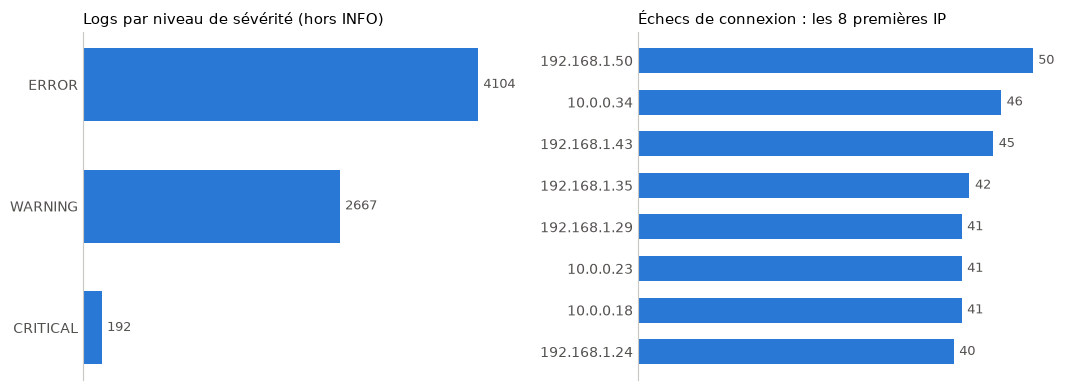

IP suspectes de brute force : ['10.0.0.14', '10.0.0.18', '10.0.0.99', '192.168.1.11', '192.168.1.22', '192.168.1.43', '192.168.1.50', '203.0.113.45']


In [15]:
BLEU = "#2a78d6"
ENCRE = "#52514e"


def barres(ax, donnees: dict, titre: str) -> None:
    tri = sorted(donnees.items(), key=lambda paire: paire[1])
    noms = [str(nom) for nom, _ in tri]
    valeurs = [valeur for _, valeur in tri]
    rects = ax.barh(noms, valeurs, color=BLEU, height=0.6)
    ax.bar_label(rects, padding=4, color=ENCRE, fontsize=9)
    ax.set_title(titre, loc="left", fontsize=11)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.spines["left"].set_color("#c9c8c2")
    ax.tick_params(axis="y", length=0, colors=ENCRE)
    ax.xaxis.set_visible(False)
    ax.margins(x=0.12)


echecs = contexte_demo["echecs_par_ip"]
top_echecs = dict(sorted(echecs.items(), key=lambda paire: paire[1], reverse=True)[:8])

fig, (gauche, droite) = plt.subplots(1, 2, figsize=(11, 4))
barres(gauche, dict(contexte_demo["occurence_error"]), "Logs par niveau de sévérité (hors INFO)")
barres(droite, top_echecs, "Échecs de connexion : les 8 premières IP")
fig.tight_layout()
plt.show()

print("IP suspectes de brute force :", sorted(contexte_demo["ip_sus_brute_force"]))